<a href="https://colab.research.google.com/github/PioPio31/AnaliticaDeDatos_Equipo1/blob/main/Practica1_U3/Actividad1_U3_PaolaIbarra23111420.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exploración del Dataset "Conjunto de datos del Centro de Servicios de Transfusión de Sangre"

Este conjunto de datos contiene información sobre 748 donantes de sangre recopilada por el Centro de Servicios de Transfusión de Sangre de la ciudad de Hsinchu, Taiwán. Los datos se utilizan para predecir si un donante volverá a donar sangre, específicamente en marzo de 2007.

Se cuenta con las siguientes descripciones de variables:
V1 (Recencia): Meses desde la última donación,
V2 (Frecuencia): Número total de donaciones,
V3 (Método monetario): Total de sangre donada (en cc),
V4 (Tiempo): Meses desde la primera donación,
Variable objetivo: Variable binaria que indica si el donante donó sangre en marzo de 2007 (1 = No, 2 = Sí).

Link de Kaggle: https://www.kaggle.com/datasets/shlokraval/blood-transfusion-service-center-data-set

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
#libreria para manipulación de datos
import pandas as pd


#libreria para calculos numericos y estadisticos
import numpy as np


#Librerias para graficar
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
#lee el archivo CSV y lo guarda en un DataFrame llamado blood_df
blood_df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/analitica datos/Unidad3/Blood Transfusion Service Center Data Set.csv')
blood_df

,V1,V2,V3,V4,Class
0,2,50,12500,98,2
1,0,13,3250,28,2
2,1,16,4000,35,2
3,2,20,5000,45,2
4,1,24,6000,77,1
...,...,...,...,...,...
744,21,2,500,52,1
745,23,3,750,62,1
746,39,1,250,39,1
747,72,1,250,72,1


In [ ]:
#muestra las dimensiones del dataframe: filas (registros) y columnas (variables).
blood_df.shape

(749, 5)

In [ ]:
# Información del dataframe: número de columnas, cuántos valores no nulos contiene cada una
# y su tipo de dato
blood_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 749 entries, 0 to 748
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      749 non-null    int64
 1   V2      749 non-null    int64
 2   V3      749 non-null    int64
 3   V4      749 non-null    int64
 4   Class   749 non-null    int64
dtypes: int64(5)
memory usage: 29.4 KB


In [ ]:
#porcentaje de valores faltantes por columna
(blood_df.isna().mean()*100)

,0
V1,0.0
V2,0.0
V3,0.0
V4,0.0
Class,0.0


Se observa que ninguna columna tiene valores faltantes, por lo que no es necesario completar ni eliminar registros por ese motivo. Esto facilita el análisis porque todas las filas tienen información disponible para las variables consideradas.

In [ ]:
#Análisis estadístico
blood_df.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,749.0,9.590120,8.406069,0.0,3.0,7.0,14.0,74.0
V2,749.0,5.508678,5.837734,1.0,2.0,4.0,7.0,50.0
V3,749.0,1377.169559,1459.433448,250.0,500.0,1000.0,1750.0,12500.0
V4,749.0,34.332443,24.399368,2.0,16.0,28.0,50.0,98.0
Class,749.0,1.237650,0.425928,1.0,1.0,1.0,1.0,2.0


In [ ]:
blood_df.skew() #sesgo
#valores positivos suelen indicar una cola hacia la derecha
#negativos, hacia la izquierda

,0
V1,2.198254
V2,3.212040
V3,3.212040
V4,0.745106
Class,1.235195


In [ ]:
blood_df.kurtosis() #curtosis
#describir que tan concentrada son las colas de la distribución

,0
V1,11.670840
V2,15.884870
V3,15.884870
V4,-0.258103
Class,-0.475570


### Interpretación del análisis estadístico

Las variables V1, V2 y V3 muestran sesgo positivo, especialmente V2 y V3. Esto también se refleja en sus valores máximos y en la curtosis elevada. V4 tiene una distribución menos sesgada. En Class, la media de 1.24 y la mediana de 1 indican que hay más registros de personas que no donaron que de personas que sí donaron.

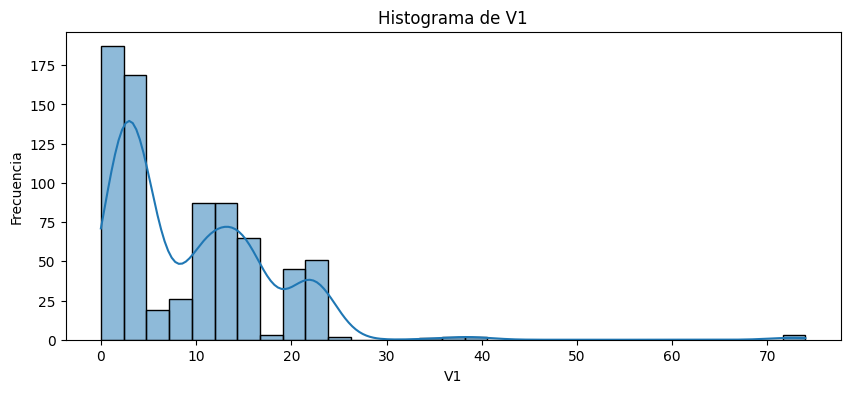

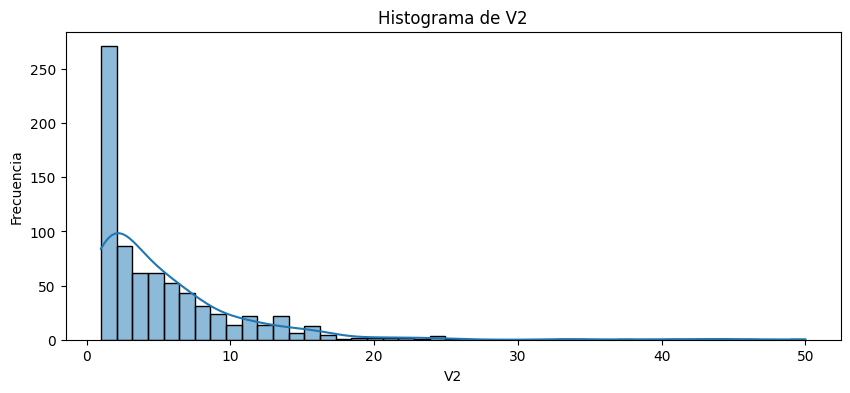

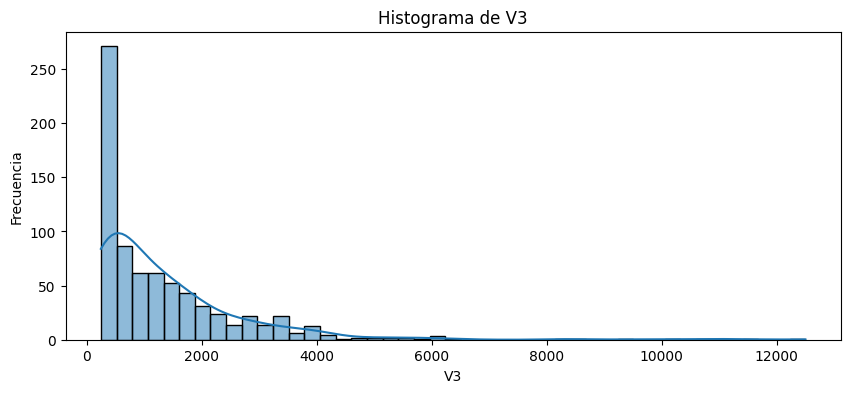

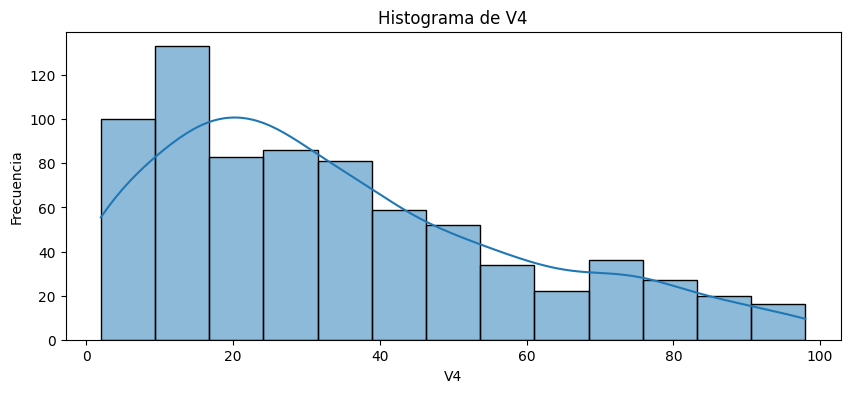

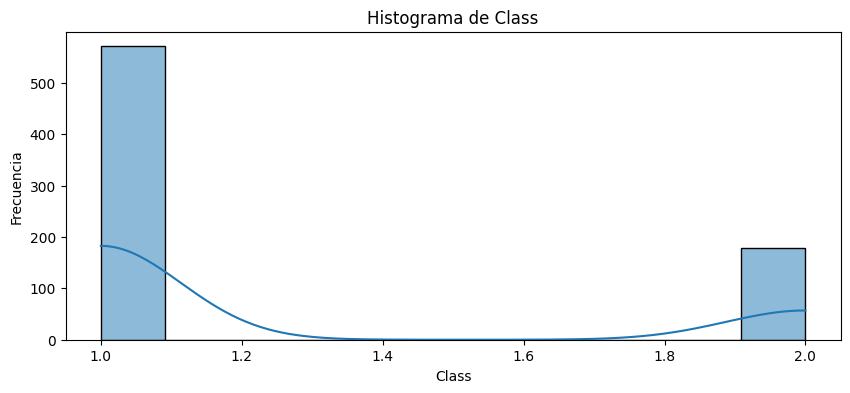

In [ ]:
numericas = blood_df[['V1','V2', 'V3', 'V4','Class']]
#Se crean histogramas de todas las variables del df
for col in numericas:
  plt.figure(figsize=(10, 4))
  sns.histplot(blood_df[col], kde=True)
  plt.title(f'Histograma de {col}')
  plt.xlabel(col)
  plt.ylabel('Frecuencia')
  plt.show()
  #El histograma muestra cuántos registros caen en cada intervalo
  #la curva KDE aproxima la forma de la distribución

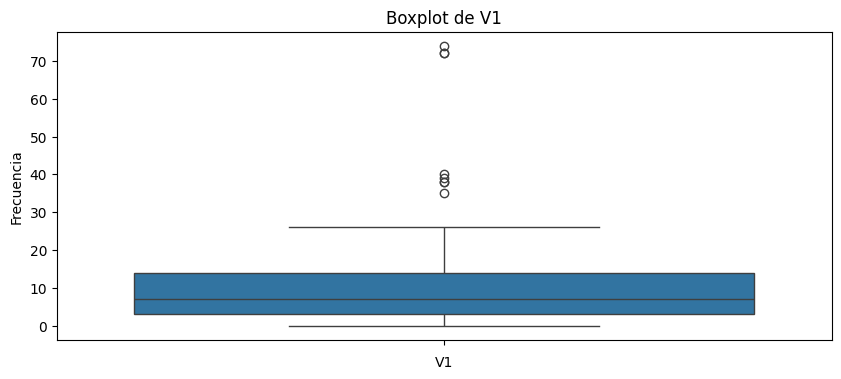

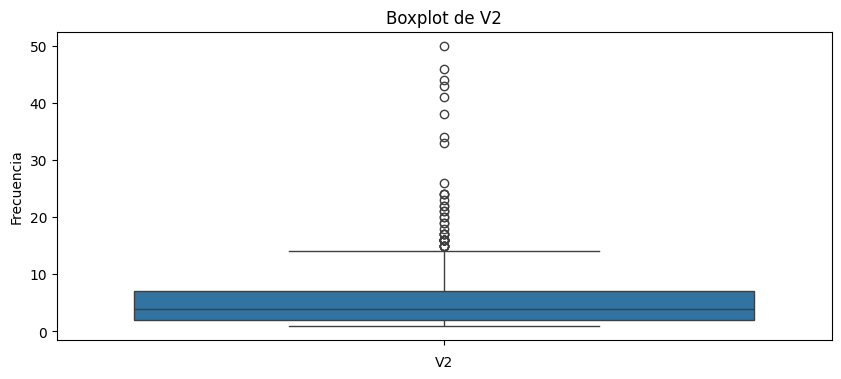

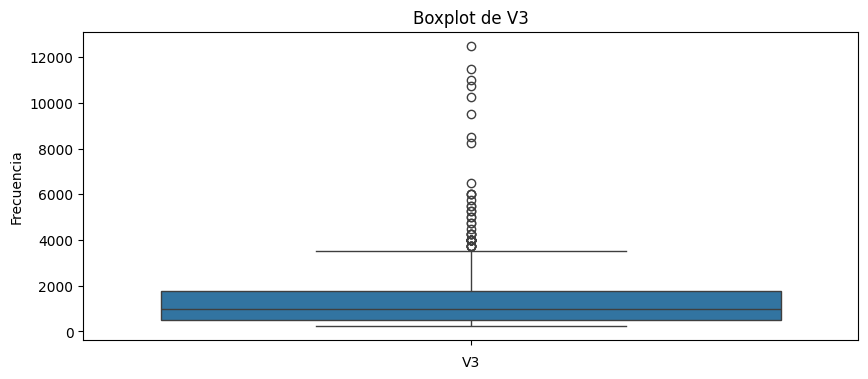

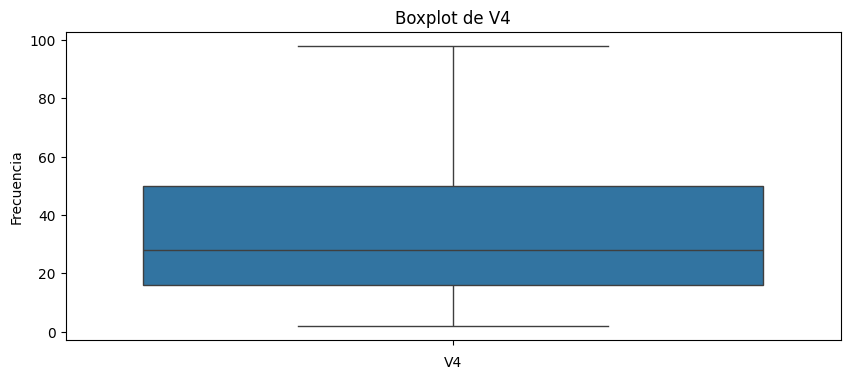

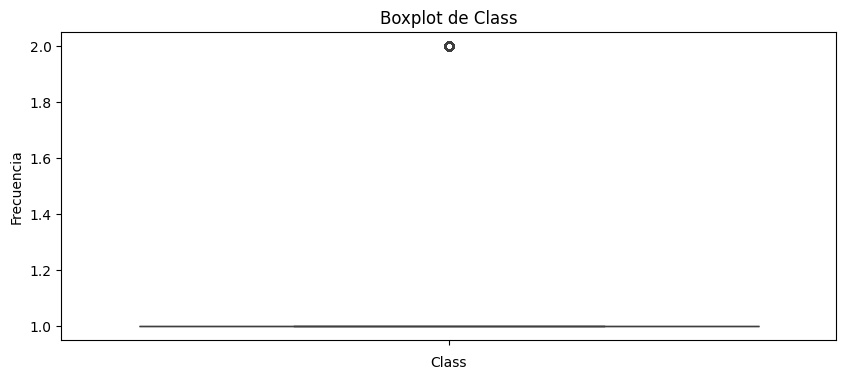

In [ ]:
#Distribución de los datos con boxplot y búsqueda de valores atípicos
for col in numericas:
  plt.figure(figsize=(10, 4))
  sns.boxplot(blood_df[col])
  plt.title(f'Boxplot de {col}')
  plt.xlabel(col)
  plt.ylabel('Frecuencia')
  plt.show()
  #Los puntos fuera de los bigotes pueden ser valores atípicos
  #no necesariamente son errores

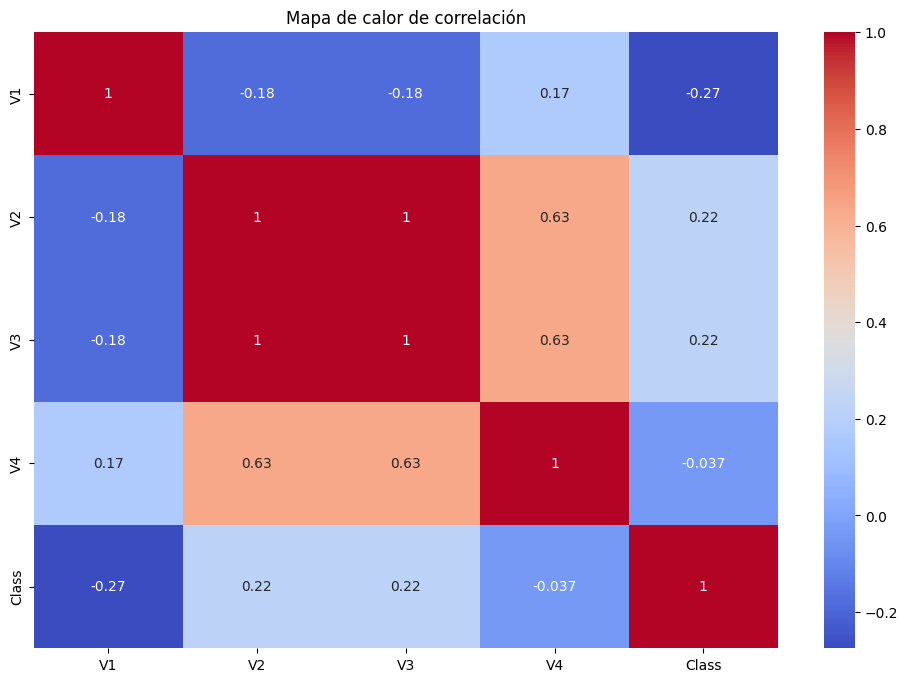

In [ ]:
#Mapa de calor para observar la correlación entre las variables del dataset
plt.figure(figsize=(12, 8))
sns.heatmap(numericas.corr(), annot=True, cmap='coolwarm')
plt.title('Mapa de calor de correlación')
plt.show()

<Axes: xlabel='V3', ylabel='V4'>

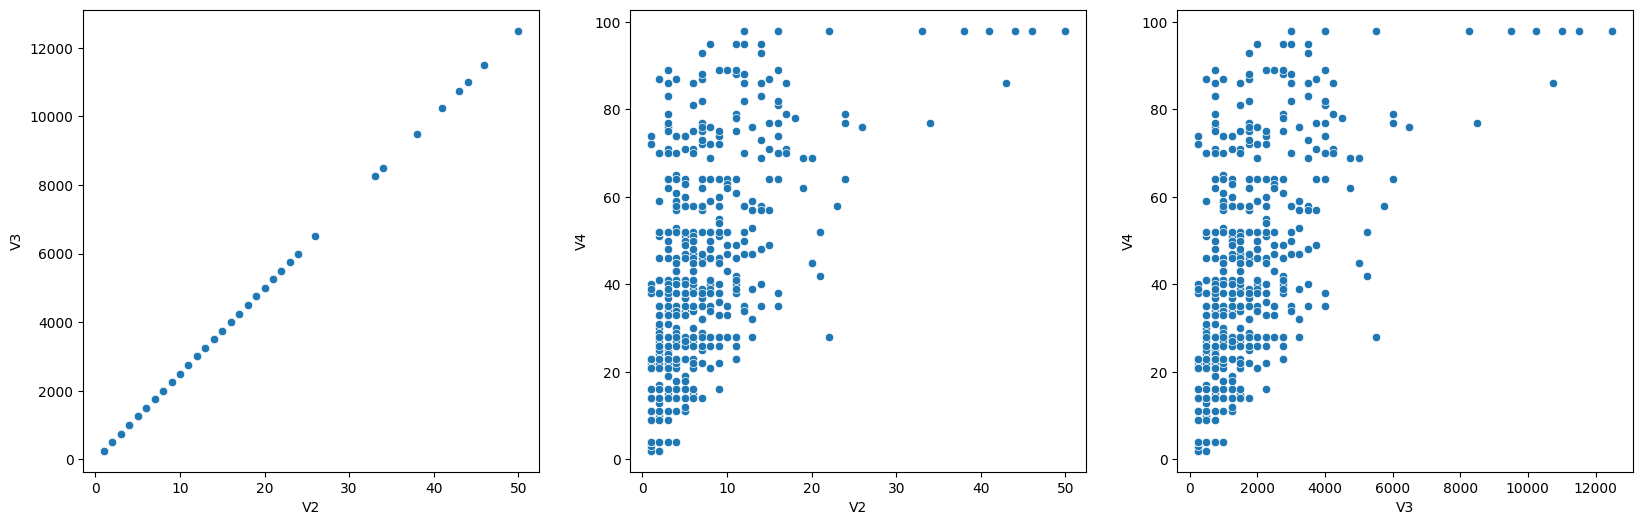

In [ ]:
#Diagramas de dispersión de variables del dataset
fig, axes = plt.subplots(1, 3, figsize = (20, 6))
sns.scatterplot(x='V2', y='V3', data=blood_df, ax=axes[0])
sns.scatterplot(x='V2', y='V4', data=blood_df, ax=axes[1])
sns.scatterplot(x='V3', y='V4', data=blood_df, ax=axes[2])
#Los diagramas de dispersión permiten observar patrones y relaciones entre V2, V3 y V4

# Aplicación del Modelo de Árbol de Decisión (Decision Tree)

In [ ]:
# Librerías importantes para la aplicación del árbol de decisión
from sklearn.tree import DecisionTreeClassifier
#from sklearn.ensemble import RandomForestClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, f1_score

#Importa el árbol de decisión, las herramientas de partición
# y las métricas para evaluar el clasificador

In [ ]:
# Preparación de los datos
X = blood_df.drop('Class', axis = 1) #variables de entrada
y = blood_df['Class'] #variable objetivo

print(X.shape)
print(y.shape)

(749, 4)
(749,)


El conjunto contiene 749 registros, cuatro variables de entrada (V1, V2, V3 y V4) y una variable de salida (Class). La variable objetivo indica si la persona donó sangre en marzo de 2007.

In [ ]:
#define las etiquetas para las dos clases de la variable objetivo
class_names = ['No donó (1)', 'Sí donó (2)']   #clase 1, clase 2

In [ ]:
# Triple partición 60/20/20
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=.2, shuffle=True, random_state=1)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=.25, shuffle=True, random_state=1)

print('Tamaño del conjunto de entrenamiento:', X_train.shape)
print('Tamaño del conjunto de validación:', X_val.shape)
print('Tamaño del conjunto de prueba', X_test.shape)
# Divide los datos en entrenamiento (60%), validación (20%) y prueba (20%)
# manteniendo la misma semilla para comparar modelos

Tamaño del conjunto de entrenamiento: (449, 4)
Tamaño del conjunto de validación: (150, 4)
Tamaño del conjunto de prueba (150, 4)


In [ ]:
# Modelo base sin poda
modeloDT = DecisionTreeClassifier()   # Incializamos el modelo con los hiperparámetros predeterminados.

clf = modeloDT.fit(X_train, y_train)   # Entrenamos con el conjunto de prueba para obtener nuestro primer clasificador (clf)

# Podemos observar el desempeño en el conjunto de entrenamieto para verificar
# el subentrenamiento o sobreentrenamiento, pero no para evaluar el modelo en sí:
print('Exactitud en el conjunto de entrenamiento: %.2f' % clf.score(X_train, y_train))

# Así, el conjunto con el que nos interesa evaluar el desempeño es con los de validación,
# así que calculamos primero sus predicciones y después las usamos para evaluar el modelo:

predi = clf.predict(X_val)

print('Exactitud en el conjunto de validación: %.2f' % clf.score(X_val, y_val))
print('Profundidad del árbol  :', clf.get_depth())
print('Número de hojas        :', clf.get_n_leaves())

Exactitud en el conjunto de entrenamiento: 0.94
Exactitud en el conjunto de validación: 0.73
Profundidad del árbol  : 19
Número de hojas        : 124


### Interpretación de los Resultados

El árbol obtuvo una exactitud de 0.73 en validación y de 0.94 en entrenamiento. Esto significa que aprendió muy bien los registros que ya conocía, pero su desempeño fue menor con datos separados. La diferencia sugiere que el árbol sin poda puede estar sobreajustándose. Además, tiene una profundidad de 19 y 124 hojas, por lo que sus reglas son bastante numerosas y complejas.

In [ ]:
#Matriz de confusión
print(confusion_matrix(y_val, predi))     # (renglones, columnas)

[[101  19]
 [ 18  12]]


### Interpretación de los Resultados

La matriz se lee por filas (clase real) y columnas (clase predicha). De los registros que realmente no donaron (clase 1), 101 se clasificaron correctamente y 19 se confundieron con donantes. De quienes sí donaron (clase 2), 12 se identificaron correctamente y 18 se clasificaron como personas que no donaron. Por tanto, el modelo reconoce mejor la clase de quienes no donaron y le cuesta identificar a quienes sí donaron.

In [ ]:
# Convierte los conteos de la matriz de confusión en proporciones del total
#de registros de validación
print(confusion_matrix(y_val, predi) / y_val.shape[0])

[[0.67333333 0.12666667]
 [0.12       0.08      ]]


### Interpretación de los Resultados

La matriz en proporciones indica que el 67.33% del conjunto corresponde a personas que no donaron y que el modelo clasificó correctamente. El 8% corresponde a donantes que sí fueron identificados correctamente. Los otros dos valores (12.67% y 12%) representan errores de clasificación. En conjunto, se observa que la mayoría de los aciertos proviene de la clase “No donó”, por lo que la exactitud por sí sola no cuenta toda la historia.

In [ ]:
#Calcula la exactitud del modelo en validación
clf.score(X_val, y_val)

0.7533333333333333

### Interpretación de los Resultados

La exactitud calculada es aproximadamente 0.753 (75.3%), aunque es un resultado general útil como referencia, la matriz de confusión muestra que el árbol tiene más dificultades para detectar a las personas que sí donaron sangre.

## Salida Gráfica del Árbol sin Podar

In [ ]:
#Librerías
# Importa las herramientas para exportar y visualizar el árbol
from sklearn import tree
import pydotplus
from IPython.display import Image
#En Colab se instala Graphviz y sus enlaces de Python
!apt-get install -y graphviz -q
!pip install pydotplus graphviz -q

Reading package lists...
Building dependency tree...
Reading state information...
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.


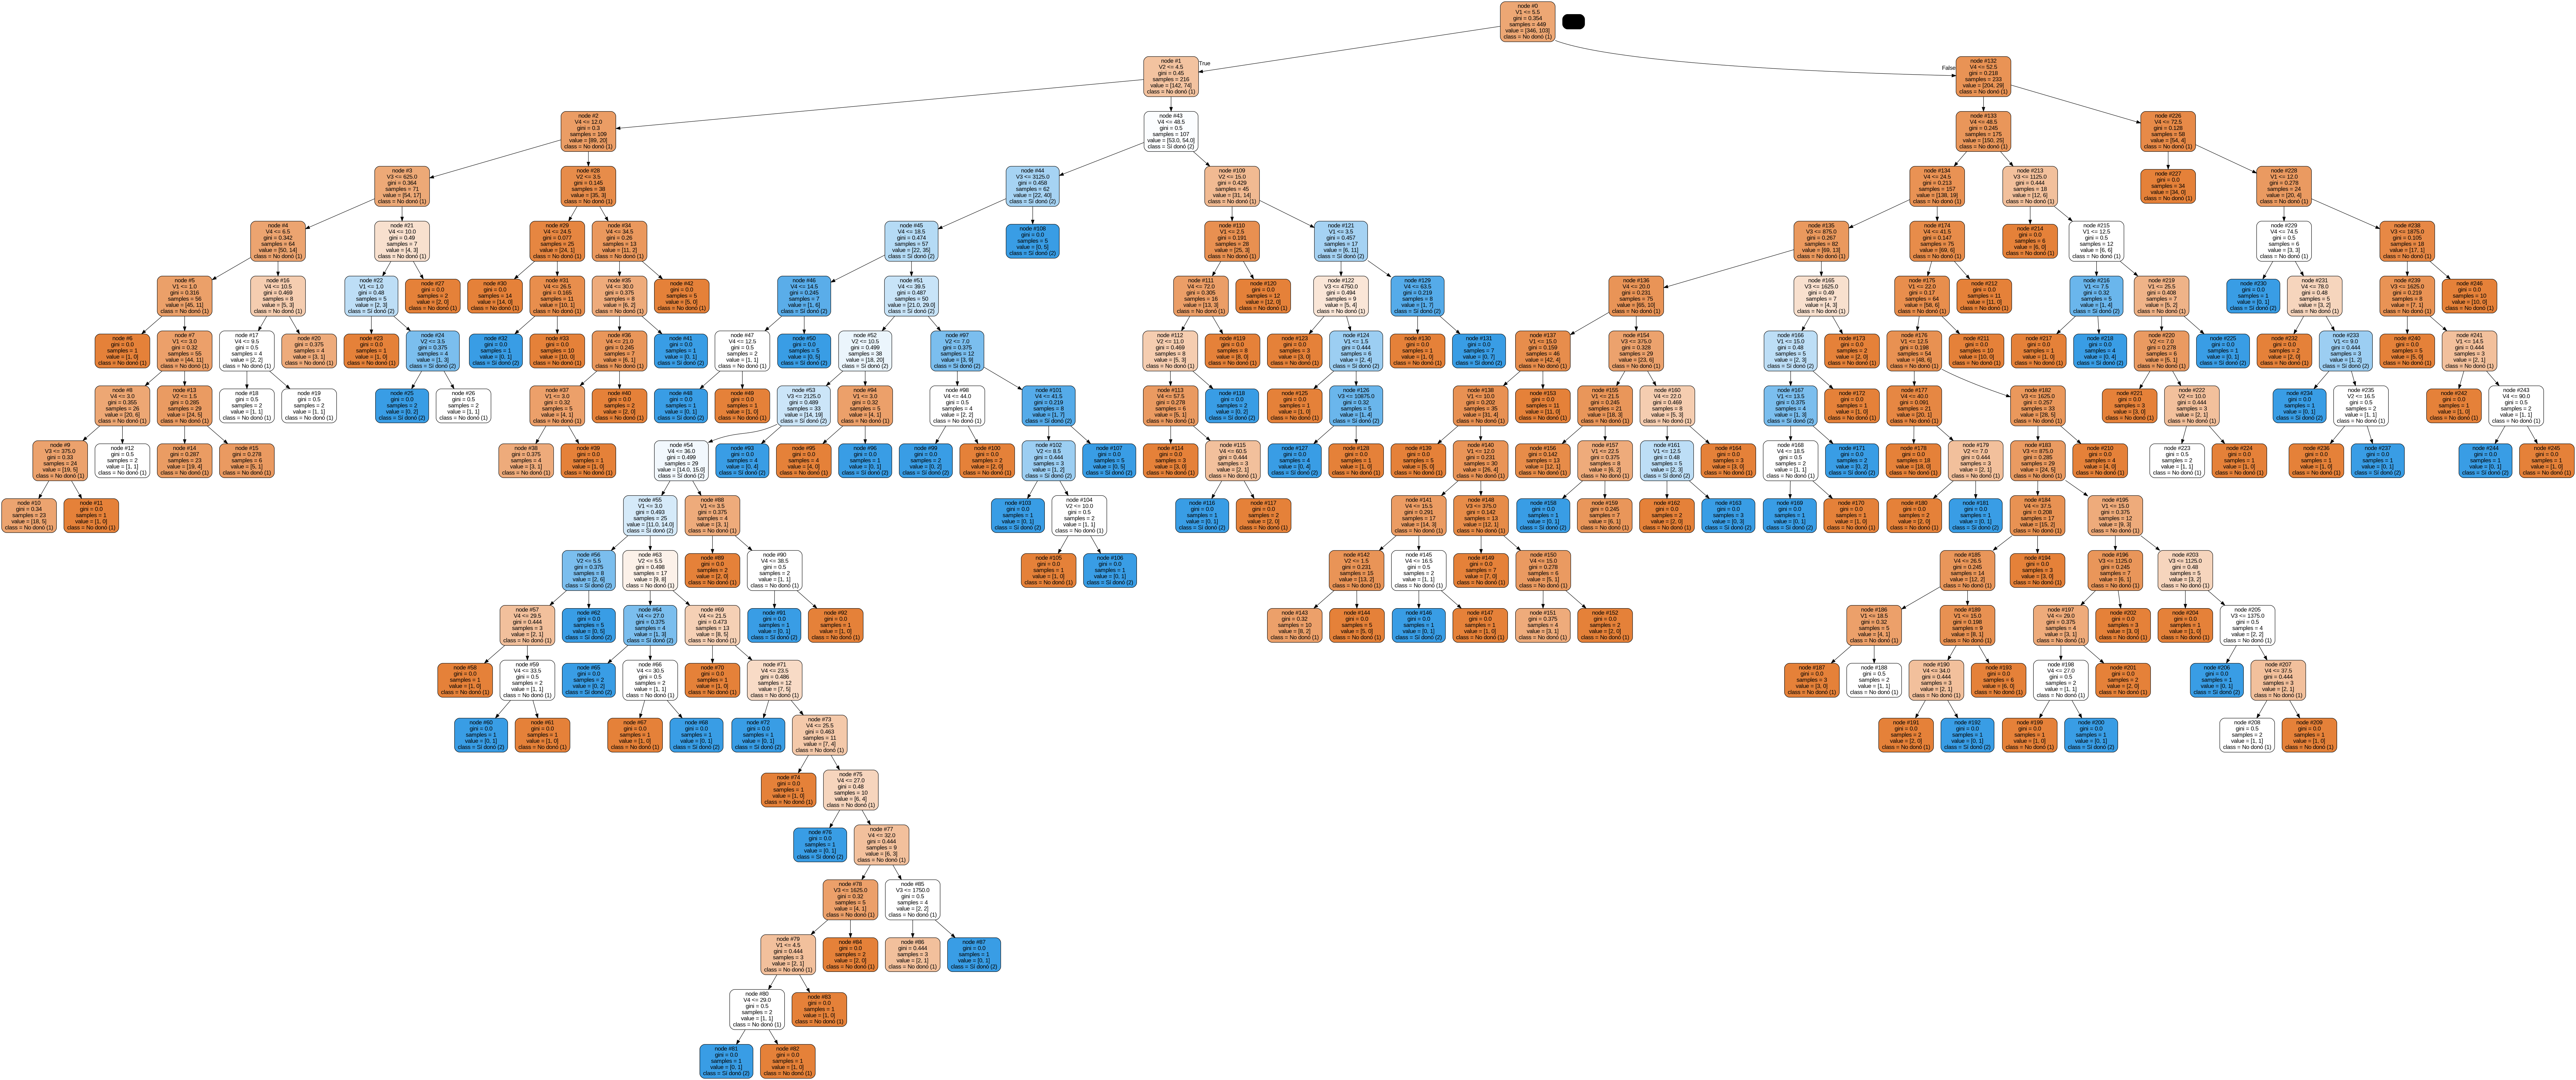

In [ ]:
# Convierte el árbol entrenado a formato DOT y lo representa como imagen
#los colores ayudan a distinguir las clases predominantes
dot_data = tree.export_graphviz(decision_tree=clf,
                                out_file=None,
                                max_depth=None,
                                feature_names=X.columns.tolist(),
                                class_names=class_names,
                                filled=True,
                                rounded=True,
                                rotate=False, #para poder verlo vertical
                                proportion=False,
                                impurity=True,
                                node_ids=True)

graph = pydotplus.graph_from_dot_data(dot_data)
Image(graph.create_png())

### Interpretación de Resultados
En el gráfico se observan las reglas que el árbol construye a partir de las variables V1, V2, V3 y V4. Cada nodo divide los registros según una condición y las hojas muestran la clase que el modelo predice al final de cada recorrido. Al ser un árbol sin poda, puede contener muchas ramas y reglas específicas, esto coincide con su profundidad de 19 y sus 124 hojas, y ayuda a explicar por qué podría ajustarse demasiado a los datos de entrenamiento.

## Aplicar Poda

### Importancia de variables

Importancia de variables: 
Variable  Importancia
      V4     0.372514
      V1     0.266829
      V2     0.237081
      V3     0.123576


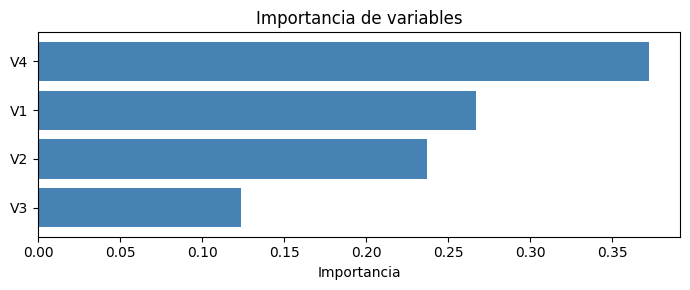


Correlación entre V2 y V3: 1.0
Ratio V3/V2 : 250.0


In [ ]:
#organiza la importancia que el árbol asigna a cada variable
importancias = pd.DataFrame({
    'Variable'   : X.columns,
    'Importancia': clf.feature_importances_
}).sort_values('Importancia', ascending=False).reset_index(drop=True)

print('Importancia de variables: ')
print(importancias.to_string(index=False))

# Gráfica de barras
plt.figure(figsize=(7,3))
plt.barh(importancias['Variable'], importancias['Importancia'], color='steelblue')
plt.xlabel('Importancia')
plt.title('Importancia de variables')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

# Correlación entre V2 y V3
print('\nCorrelación entre V2 y V3:', round(blood_df[['V2','V3']].corr().iloc[0,1], 4))
print('Ratio V3/V2 :', round((blood_df['V3']/blood_df['V2']).mean(), 2))

Se elimina V3 por ser redundante con V2.

In [ ]:
# Nuevo dataset sin V3
X2 = blood_df.drop(columns=['Class', 'V3'])
y2 = blood_df['Class']

# Misma triple partición, mismo random_state para comparar limpio
X2_tv, X2_test, y2_tv, y2_test = train_test_split(X2, y2, test_size=0.2, shuffle=True, random_state=1)
X2_train, X2_val, y2_train, y2_val = train_test_split(X2_tv, y2_tv, test_size=0.25, shuffle=True, random_state=1)

print('Tamaño del conjunto de entrenamiento:', X_train.shape)
print('Tamaño del conjunto de validación:', X_val.shape)
print('Tamaño del conjunto de prueba', X_test.shape)

Tamaño del conjunto de entrenamiento: (449, 4)
Tamaño del conjunto de validación: (150, 4)
Tamaño del conjunto de prueba (150, 4)


In [ ]:
#Entrena un árbol sin poda usando las variables restantes
clf_sinpoda_v2 = DecisionTreeClassifier(random_state=1)
clf_sinpoda_v2.fit(X2_train, y2_train)

print('Sin V3 y sin poda')
print(f'Entrenamiento: {clf_sinpoda_v2.score(X2_train, y2_train):.4f}')
print(f'Validación: {clf_sinpoda_v2.score(X2_val,   y2_val):.4f}')
print(f'Profundidad: {clf_sinpoda_v2.get_depth()}')
print(f'Hojas: {clf_sinpoda_v2.get_n_leaves()}')

Sin V3 y sin poda
Entrenamiento: 0.9443
Validación: 0.7400
Profundidad: 19
Hojas: 124


### Interpretación de resultados

Al quitar V3, el árbol mantiene una exactitud de 0.9443 en entrenamiento y 0.7400 en validación, con profundidad 19 y 124 hojas. El resultado es muy parecido al árbol original, así que eliminar V3 no cambia mucho el desempeño.

In [ ]:
# Modelo mejorado con poda
# Probar combinaciones de hiperparámetros con validación cruzada
# de 5 partes para encontrar un árbol más simple
param_grid = {
    'max_depth'         : [3, 4, 5, 6, None],
    'min_samples_split' : [2, 5, 10, 20],
    'min_samples_leaf'  : [1, 3, 5, 10],
    'ccp_alpha'         : [0.0, 0.001, 0.01, 0.1]
}

grid = GridSearchCV(
    estimator = DecisionTreeClassifier(random_state=1),
    param_grid= param_grid,
    cv        = 5,
    scoring   = 'accuracy',
    n_jobs    = -1
)
grid.fit(X2_train, y2_train)

print('Mejores hiperparámetros (sin V3)')
print(grid.best_params_)
print(f'Mejor score CV: {grid.best_score_:.4f}')

clf_podado = grid.best_estimator_

Mejores hiperparámetros (sin V3)
{'ccp_alpha': 0.0, 'max_depth': 3, 'min_samples_leaf': 3, 'min_samples_split': 2}
Mejor score CV: 0.7995


### Interpretación de resultados

La búsqueda con validación cruzada eligió un árbol con profundidad máxima de 3, mínimo de 3 registros por hoja y ccp_alpha = 0.0. Su mejor exactitud media en la validación cruzada fue de 0.7995 (79.95%). Aunque la poda por coste-complejidad no quedó activa con ese valor de ccp_alpha, limitar la profundidad reduce la complejidad del árbol. Los hiperparámetros seleccionados son los que dieron el mejor resultado promedio entre las combinaciones probadas.

In [ ]:
# Evaluación del modelo podado en validación
predi_val = clf_podado.predict(X2_val)

print('Modelo podado sin V3')
print(f'Entrenamiento: {clf_podado.score(X2_train, y2_train):.4f}')
print(f'Validación: {clf_podado.score(X2_val,   y2_val):.4f}')
print(f'Brecha: {clf_podado.score(X2_train, y2_train) - clf_podado.score(X2_val, y2_val):.4f}')
print(f'Profundidad: {clf_podado.get_depth()}')
print(f'Hojas: {clf_podado.get_n_leaves()}')

print('\nMatriz de confusión')
print(confusion_matrix(y2_val, predi_val))

print('\nProporciones:')
print(np.round(confusion_matrix(y2_val, predi_val) / y2_val.shape[0], 4))

print('\nReporte por clase')
print(classification_report(y2_val, predi_val,
                            target_names=class_names, digits=3))

Modelo podado sin V3
Entrenamiento: 0.8107
Validación: 0.7867
Brecha: 0.0240
Profundidad: 3
Hojas: 8

Matriz de confusión
[[106  14]
 [ 18  12]]

Proporciones:
[[0.7067 0.0933]
 [0.12   0.08  ]]

Reporte por clase
              precision    recall  f1-score   support

 No donó (1)      0.855     0.883     0.869       120
 Sí donó (2)      0.462     0.400     0.429        30

    accuracy                          0.787       150
   macro avg      0.658     0.642     0.649       150
weighted avg      0.776     0.787     0.781       150



### Interpretación de resultados
El modelo podado obtuvo 81.07% de exactitud en entrenamiento y 78.67% en validación. La diferencia entre ambas es de solo 2.4 puntos porcentuales, bastante menor que en el árbol sin podar, lo que sugiere una mejor capacidad de generalización. Además, pasó de 19 niveles de profundidad y 124 hojas a una profundidad de 3 y 8 hojas, por lo que es más sencillo de interpretar.

La matriz de confusión indica que identificó correctamente a 106 personas que no donaron y a 12 que sí donaron. Para la clase “Sí donó”, el recall es 0.400, es decir, detectó el 40% de los casos positivos; todavía dejó sin identificar a 18 donantes. Su precisión para esa clase fue 0.462, por lo que menos de la mitad de las predicciones de “Sí donó” fueron correctas. En consecuencia, el modelo podado mejora el equilibrio general y reduce el sobreajuste, pero sigue teniendo dificultades con la clase de personas que sí donaron.


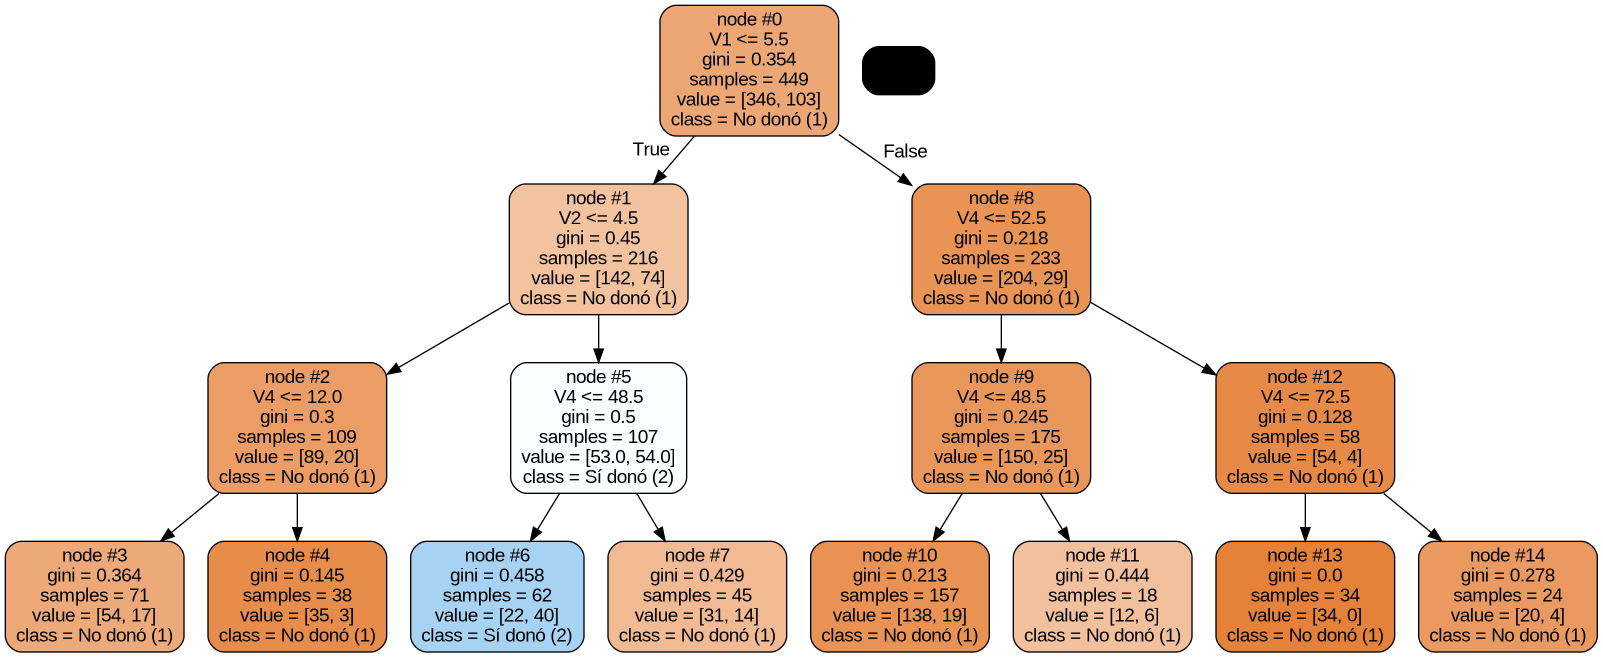

In [ ]:
#Gráfica del árbol podado sin V3
dot_data = tree.export_graphviz(
    decision_tree = clf_podado,
    out_file = None,
    max_depth = None,
    feature_names = X2.columns.tolist(),
    class_names = class_names,
    filled = True,
    rounded = True,
    rotate = False,
    proportion = False,
    impurity = True,
    node_ids = True
)
Image(pydotplus.graph_from_dot_data(dot_data).create_png())

### Interpretación de resultados

El árbol podado tiene menos divisiones y hojas que el árbol original, por lo que sus reglas son más fáciles de seguir. Cada recorrido desde la parte superior hasta una hoja representa una serie de condiciones sobre las variables restantes (V1, V2 y V4). Esta simplificación concuerda con la menor diferencia entre entrenamiento y validación. Aun así, como el modelo solo detecta el 40% de los casos de la clase “Sí donó”, sus predicciones no deberían considerarse suficientes por sí solas para tomar decisiones sobre posibles donantes.

## Conclusión

En conclusión, al trabajar con el modelo de árbol de decisión pude comprender mejor cómo se pueden utilizar los datos para predecir si una persona realizará una donación de sangre. Al comparar el árbol sin podar con el árbol podado, observé que reducir su complejidad puede ayudar a que el modelo sea más sencillo de interpretar, aunque esto no garantiza que sus predicciones sean mejores. También comprendí que no basta con revisar la exactitud para saber si un modelo funciona bien, sino que es importante analizar sus errores y qué tan bien identifica cada clase. En general, esta actividad me ayudó a entender mejor el funcionamiento de los árboles de decisión y la importancia de evaluar los resultados antes de considerar que un modelo es adecuado.

# Bosque Aleatorio (Random Forest)

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score

In [8]:
# X = las 4 variables predictoras (V1, V2, V3, V4)
X = blood_df[['V1', 'V2', 'V3', 'V4']]

# Y = la variable objetivo (Class: 1 = No donó, 2 = Sí donó)
Y = blood_df['Class']

# Dividir en entrenamiento (60%) y prueba (40%)
Xtrain, Xtest, Ytrain, Ytest = train_test_split(
    X, Y, test_size=0.4, shuffle=True, random_state=17
)

In [9]:
# Modelo random forest
mimodelo = RandomForestClassifier(
    n_estimators=10,        # número de árboles
    criterion='gini',       # métrica para ramificar
    max_depth=2,            # profundidad máxima
    min_samples_split=6,    # mínimo de muestras para dividir un nodo
    min_samples_leaf=4,     # mínimo de muestras en cada hoja
    max_leaf_nodes=16,      # máximo de hojas
    bootstrap=True,         # muestreo con reemplazo
    oob_score=True,         # usar muestras out-of-bag
    n_jobs=-1,              # usar todos los hilos
    random_state=19
)

# Entrenar
clf = mimodelo.fit(Xtrain, Ytrain)

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_forest.py:612: UserWarning: Some inputs do not have OOB scores. This probably means too few trees were used to compute any reliable OOB estimates.
  warn(


In [10]:
# Predicciones
results = clf.predict(Xtest)

# Matriz de confusión
print("Matriz de confusión:")
print(confusion_matrix(Ytest, results))

# Exactitud (accuracy)
print("\nExactitud:", clf.score(Xtest, Ytest))

Matriz de confusión:
[[233   1]
 [ 64   2]]

Exactitud: 0.7833333333333333


Importancias: [0.2784084  0.35547375 0.14240546 0.22371239]


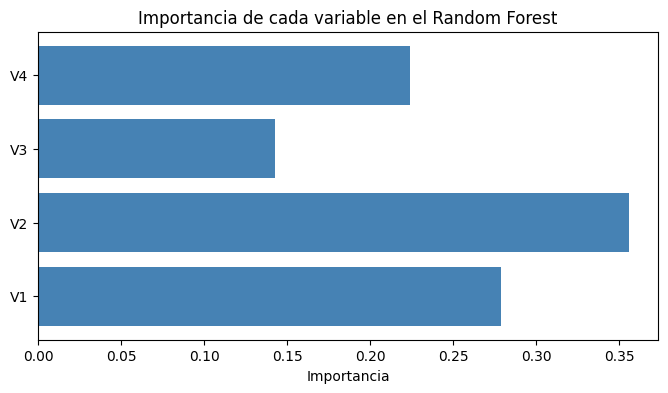

In [13]:
# Importancia de cada factor
importancias = clf.feature_importances_
print("Importancias:", importancias)

# Gráfico de barras horizontales
plt.figure(figsize=(8, 4))
plt.barh(['V1', 'V2', 'V3', 'V4'], width=importancias, color='steelblue')
plt.xlabel('Importancia')
plt.title('Importancia de cada variable en el Random Forest')
plt.show()

In [12]:
mimodelo2 = RandomForestClassifier(
    n_estimators=100,       # número de árboles
    criterion='gini',       # métrica para ramificar
    max_depth=None,         # sin límite de profundidad
    random_state=19
)
clf2 = mimodelo2.fit(Xtrain, Ytrain)
print("Exactitud modelo2:", clf2.score(Xtest, Ytest))

Exactitud modelo2: 0.7333333333333333


### Interpretación de resultados

El modelo Random Forest con los parámetros del ejemplo (max_depth=2 y 10 árboles) obtuvo una exactitud del 78.3%. Sin embargo, este resultado no refleja del todo su desempeño, ya que los datos están desbalanceados. El modelo logró identificar correctamente a casi todas las personas que no donarían (233 de 234), pero tuvo muchas dificultades para reconocer a quienes sí donarían, pues solo identificó a 2 de las 66 personas. Por otro lado, el segundo modelo, configurado con 100 árboles y sin límite de profundidad, obtuvo una exactitud menor del 73.3%. Esto se debe a que intentó identificar mejor a las personas que sí donarían, aunque a cambio cometió más errores al clasificar a quienes no lo harían.


## Conclusión
Aunque ambos modelos obtuvieron una exactitud similar, cercana al 78%, el árbol de decisión podado ofrece mejores resultados para el objetivo del problema, ya que logra identificar una mayor cantidad de donantes que vuelven a realizar una donación (recall de 0.40). Esto significa que el bosque tiene dificultades para reconocer a los donantes recurrentes y tiende a clasificar la mayoría de los casos como parte de la clase más frecuente.
Además, el árbol podado presenta una diferencia muy pequeña entre los resultados de entrenamiento y validación (0.024), lo que indica que mantiene un buen equilibrio y evita el sobreajuste, incluso con una profundidad de 3 y 8 hojas.
En conclusión, para este conjunto de datos, que presenta un desbalance entre clases, el árbol de decisión podado resulta más adecuado que el Random Forest.